# The WDM wavelet response against `fastlisaresponse` and `lisagwresponse`

This package computes the LISA response directly on a Wilson–Daubechies–Meyer
wavelet grid, never returning to a time series. `fastlisaresponse` and
`lisagwresponse` (with `pytdi` for TDI) compute it in the time domain. This
notebook puts second-generation TDI from all of them beside each other on one
galactic binary, with our own slow time-domain path as the reference.

All codes are fed the same array — the tapered, zero-padded record — and read
the same orbit file. The `fastlisaresponse` and
`lisagwresponse` packages return a fractional frequency shift and we return a
delay; section 7 builds the conversion between the two, step by step.

> **Environment note.** Needs `fastlisaresponse` ≥ 1.2.1a0; earlier releases
> have the opposite link sign. On macOS, `lisatools` and `fastlisaresponse` each
> ship their own `libstdc++.6.dylib`, and loading both aborts the interpreter
> with `Abort trap: 6`. Point one at the other before running this notebook:
>
> ```bash
> cd .../site-packages/fastlisaresponse/.dylibs
> mv libstdc++.6.dylib libstdc++.6.dylib.bak
> ln -s ../../lisatools/.dylibs/libstdc++.6.dylib libstdc++.6.dylib
> ```
>
> It does not survive reinstalling either package.

In [1]:
# Run BEFORE anything imports fastlisaresponse. The failure this guards
# against is a SIGABRT -- the interpreter dies with no traceback and nothing
# to say why -- so the only useful moment to look is beforehand.
from WDM_LISAresponse.code.comparison import conventions_flr

print(conventions_flr.check_environment())

no vendored-runtime clash: the two packages can share a process


In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt

from fastlisaresponse import pyResponseTDI
from lisatools.detector import Orbits
from lisagwresponse import ReadStrain
from pytdi import Data
from pytdi.michelson import X2, Y2, Z2

from WDM_LISAresponse.code.comparison import common, config, conventions_gwr
from WDM_LISAresponse.code.comparison.tdi import TDIgen2
from WDM_LISAresponse.code.comparison.tdi_reference import gen2_xyz_time_domain
from WDM_LISAresponse.code.utils.utils import apply_wdm_cut, apply_zero_padding, wdm_mismatch
from WDM.code.plotting.plotting import time_frequency_plot

## 1. Configuration

Every number defining the study lives in `config`, so the pipelines cannot
drift onto different grids, sources or orbits.

`SHORT` is a thirty-day record and runs in about a minute. `DEFAULT` is the
real 485-day one; its time-domain reference section takes up to 10 minutes.

In [3]:
cfg = config.DEFAULT   #config.SHORT for the 30-day record, config.DEFAULT for the full 485-day record 
print(cfg.summary())

cadence          dt = 10 s
bands            Nf = 128
rows             Nt = 32768
padded length     N = 4194304 (485.5 d)
signal length      = 4180992 (483.9 d)
tiling           dT = 1280 s, dF = 3.906250e-04 Hz
source        m = 13, f = 5.078125 mHz
tukey alpha      = 0.01
guard         52 rows per side (2x default; L = 51)
interp points    = 256
reference nodes   P = 12
grid memory      = 32.0 MiB per (Nt, Nf) grid
orbits           = esa
orbit file       = esa-trailing-orbits.h5
epoch            t0 = 2.07321e+09 s


The numbers worth noticing:

- **`m = 13`** puts the binary at a bin centre, so it occupies a single wavelet
  row, which keeps the residual legible. Off-bin sources are worse; see
  `accuracy_analysis.ipynb`.
- **`L = 51`** rather than the usual 25, for accuracy. The cost is double the
  runtime.
- **52 guard rows per side**, twice the package default. The signal passes
  through two variable time shifts — the response, then TDI — and padding
  $\geq L$ keeps both from wrapping into the analysed region.
- **`P = 12`** Gauss-Legendre nodes for the time-domain reference, the package
  default. Four already reach the $1.3\times10^{-10}$ floor at this frequency
  on the ESA orbits; twelve cover the LISA band to 0.1 Hz.

## 2. The source

One galactic binary, generated once. Every pipeline is fed this same array,
tapered and zero-padded, so the waveform cannot contribute to any
disagreement.

In [4]:
h_plus, h_cross = cfg.waveform()
_, h_plus, h_cross = apply_zero_padding(
    cfg.signal_times, h_plus, h_cross,
    cfg.padding["pad_left"], cfg.padding["pad_right"],
)

wdm, response = cfg.build()
w_plus, w_cross = wdm.dwt(h_plus), wdm.dwt(h_cross)

power = np.asarray(w_plus) ** 2
per_row = power.sum(axis=0) / power.sum()
print(f"power in row {cfg.m_bin}: {per_row[cfg.m_bin]:.9f}")
print(f"everything else:       {1 - per_row[cfg.m_bin]:.3e}")

power in row 13: 1.000000000
everything else:       4.408e-14


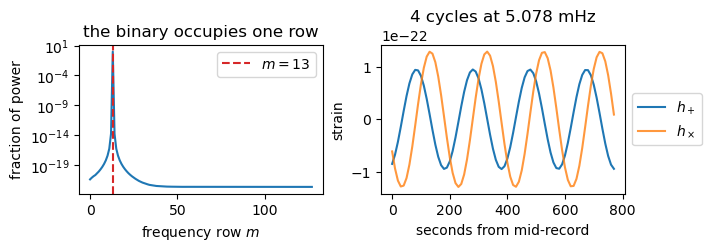

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(7, 2.4), layout="constrained")

ax[0].semilogy(per_row)
ax[0].axvline(cfg.m_bin, color="C3", ls="--", label=f"$m = {cfg.m_bin}$")
ax[0].set(xlabel="frequency row $m$", ylabel="fraction of power",
          title="the binary occupies one row")
ax[0].legend()

# A sub-range: the full record holds thousands of cycles and plots as a solid block.
n_cycles = 4
span = int(n_cycles / cfg.f_gb / cfg.dt)
sl = slice(cfg.N // 2, cfg.N // 2 + span)
seconds = cfg.padded_times[sl] - cfg.padded_times[cfg.N // 2]

ax[1].plot(seconds, h_plus[sl], label="$h_+$")
ax[1].plot(seconds, h_cross[sl], alpha=0.8, label=r"$h_\times$")
ax[1].set(xlabel="seconds from mid-record", ylabel="strain",
          title=f"{n_cycles} cycles at {cfg.f_gb * 1e3:.3f} mHz")
ax[1].legend(loc="center left", bbox_to_anchor=(1, 0.5))

## 3. This package: response, then TDI

Six link responses on the wavelet grid, then the second-generation combination
— sixteen terms per channel, of which fourteen need a shift, so 42 for XYZ.

Each term is *one* shift of an original link grid, never a chain of them:
composed delay operators are a single time reparametrisation, so even the
seven-arm chains cost one call.

In [6]:
start = time.perf_counter()
links = response(cfg.theta, cfg.phi, w_plus, w_cross)
tdi = TDIgen2(response)
ours = np.asarray(tdi(links))
elapsed = time.perf_counter() - start

print(f"links {links.shape}   XYZ {ours.shape}   {elapsed:.1f} s")
print(tdi.delay_summary().splitlines()[0])

links (6, 32768, 128)   XYZ (3, 32768, 128)   30.5 s
42 distinct chains, 42 shifts per call


## 4. The internal reference

The *same* source through the slow time-domain path — Gauss-Legendre integration
along the null geodesic, then TDI with interpolated delays — which makes no
local-delay approximation at all.

This cell is the expensive one. Most of its cost is the reference TDI rather
than the reference response: it re-solves the geometry on all $N$ sample times
for 42 distinct delay chains.

In [7]:
start = time.perf_counter()
links_td = np.asarray(response.one_arm_response_time_domain(
    cfg.theta, cfg.phi, h_plus, h_cross, num_integral_points=cfg.num_integral_points))
reference = gen2_xyz_time_domain(response, links_td)
reference = np.stack([np.asarray(wdm.dwt(row)) for row in reference])
print(f"reference path: {time.perf_counter() - start:.1f} s")

reference path: 538.5 s


## 5. `fastlisaresponse`

`pyResponseTDI` takes the record directly. Its clock starts at the orbit file's
first sample, so `t0` is passed as the time from there to ours. Both codes read
the same orbit file.

In [8]:
orbits = Orbits(cfg.orbit_file)
orbits.configure(linear_interp_setup=True)

start = time.perf_counter()
_, flr_xyz = conventions_flr.run(pyResponseTDI, orbits, cfg, h_plus, h_cross, cfg.theta, cfg.phi)
print(f"XYZ {flr_xyz.shape}   {time.perf_counter() - start:.1f} s")

XYZ (3, 4194304)   8.0 s


## 6. `lisagwresponse` and `pytdi`

`lisagwresponse` takes the record and our sample times directly. `pytdi` forms
TDI from its link responses, with delays from the orbit file's TCB light travel
times — its default is spacecraft proper time, which is not what our geometry
uses.

In [9]:
start = time.perf_counter()
gwr_links = conventions_gwr.links(ReadStrain, cfg, h_plus, h_cross, cfg.theta, cfg.phi)
gwr_xyz = conventions_gwr.channels(Data, (X2, Y2, Z2), cfg, gwr_links)
print(f"XYZ {gwr_xyz.shape}   {time.perf_counter() - start:.1f} s")

XYZ (3, 4194304)   115.9 s


## 7. From their frequency shift to our delay

Our delay is Cornish & Rubbo's Eq. 12,

$$\delta\ell(t) = A(t) : \int_{\xi_i(t)}^{\xi_j(t)} h(\xi)\,\mathrm{d}\xi ,
\qquad A = \frac{\hat{r}\otimes\hat{r}}{2(1 - \hat{\Omega}\cdot\hat{r})} ,$$

with limits the retarded wave phase $\xi = t - \hat{\Omega}\cdot x/c$ at
emission $i$ and reception $j$. The external codes return the fractional
frequency shift of the received light instead. Light received at $t$ left at
$t - \ell(t)$, so it carries the laser phase emitted then,
$\Phi_\mathrm{rec}(t) = \Phi_\mathrm{em}(t - \ell(t))$. Differentiating,
$\nu_\mathrm{rec} = \nu_\mathrm{em}\,(1 - \mathrm{d}\ell/\mathrm{d}t)$, so
$y = (\nu_\mathrm{rec} - \nu_\mathrm{em})/\nu_\mathrm{em} = -\mathrm{d}\ell/\mathrm{d}t$:
a growing delay lowers the received frequency.

Differentiating with the constellation frozen — $A$ held fixed, the limits
moving at rate 1 — gives $y = -A : (h_j - h_i) = A : (h_\mathrm{em} - h_\mathrm{rec})$,
which is their formula. Their polarisation basis is also ours turned by 90°
($\hat{u}_\mathrm{theirs} = \hat{v}$, $\hat{v}_\mathrm{theirs} = -\hat{u}$),
flipping both antenna patterns, so the two signs cancel and theirs is
$+\mathrm{d}/\mathrm{d}t$ of ours.

First the raw amplitudes. The ratio is the same on all three channels, and it
is $2\pi f$ — the signature of a time derivative, not a scale factor. The
mismatch of $\approx 1$ says the same thing from the other side:
differentiating a tone rotates its phase by $90^\circ$, leaving the two records
orthogonal.

In [14]:
dead = max(conventions_flr.dead_samples(cfg), conventions_gwr.dead_samples(cfg))
cut = common.interior(cfg, dead)

print(f"2*pi*f = {2 * np.pi * cfg.f_gb:.6f}")
print(f"{'code':<5} {'ch':<3} {'raw ratio':>11} {'mismatch':>11}")
for code, raw in (("flr", flr_xyz), ("gwr", gwr_xyz)):
    for name, mine, other in zip("XYZ", ours, raw):
        a, b = apply_wdm_cut(mine, cut), apply_wdm_cut(np.asarray(wdm.dwt(other)), cut)
        ratio = np.sqrt(np.mean(b ** 2)) / np.sqrt(np.mean(a ** 2))
        print(f"{code:<5} {name:<3} {ratio:>11.6f} {wdm_mismatch(a, b)['mismatch']:>11.3e}")

2*pi*f = 0.031907
code  ch    raw ratio    mismatch
flr   X      0.031907   1.000e+00
flr   Y      0.031907   1.000e+00
flr   Z      0.031907   1.000e+00
gwr   X      0.031907   1.000e+00
gwr   Y      0.031907   1.000e+00
gwr   Z      0.031907   1.000e+00


So the conversion is a time integral, taken spectrally and applied to *their*
output alone, giving the columns `flr` and `gwr`.

In [15]:
factor = common.velocity_factor(response.orbits_class, cfg.padded_times, cfg.theta, cfg.phi)
print(f"1 - Omega.v/c over the record: {factor.min():.7f} to {factor.max():.7f}\n")

grids = {
    "wavelet": ours,
    "reference": reference,
    "flr": common.convert(flr_xyz, cfg, wdm),
    "gwr": common.convert(gwr_xyz, cfg, wdm),
}

print(common.report(grids, cut, "wavelet"), end="\n\n")
print(common.report(grids, cut, "reference"), end="\n\n")
print(common.report({name: grids[name] for name in ("flr", "gwr")}, cut, "flr"))

1 - Omega.v/c over the record: 0.9999447 to 1.0000553

against wavelet
ch  measure     reference        flr        gwr
X   rel_L2       3.97e-05   6.07e-05   6.07e-05
    mismatch     7.89e-10   1.72e-09   1.71e-09
Y   rel_L2       3.35e-05   5.52e-05   5.53e-05
    mismatch     5.59e-10   1.46e-09   1.46e-09
Z   rel_L2       4.17e-05   6.19e-05   6.18e-05
    mismatch     8.54e-10   1.89e-09   1.88e-09

against reference
ch  measure       wavelet        flr        gwr
X   rel_L2       3.97e-05   3.89e-05   3.90e-05
    mismatch     7.89e-10   6.19e-10   6.16e-10
Y   rel_L2       3.35e-05   3.97e-05   3.98e-05
    mismatch     5.59e-10   7.35e-10   7.37e-10
Z   rel_L2       4.17e-05   3.82e-05   3.83e-05
    mismatch     8.54e-10   7.29e-10   7.29e-10

against flr
ch  measure           gwr
X   rel_L2       1.46e-06
    mismatch     1.03e-12
Y   rel_L2       1.38e-06
    mismatch     8.92e-13
Z   rel_L2       1.25e-06
    mismatch     7.39e-13


Against the reference, in `rel_L2`, both external codes sit at
$\approx 4\times10^{-5}$ and agree with each other to $\sim10^{-6}$. The gap is
the frozen constellation: the limits really move at
$1 - \hat{\Omega}\cdot\mathbf{v}/c$, with $\mathbf{v}$ the spacecraft
velocity, and the external formula drops that factor. Over the year it swings
by $\pm 5.5\times10^{-5}$, printed above, and its RMS is the gap. Restoring it
with the mean velocity of the three spacecraft, checked separately, brings both
to $\sim 6\times10^{-6}$; the rest is the two ends of each arm moving
differently and $A$ turning with the arm, growing as $1/f$. Against the wavelet
path the reference sits at $3$–$4\times10^{-5}$, the local-delay approximation:
over a full year, the same size as the dropped factor.

## 8. What the records look like

Channel X on the wavelet grid for each method, then the differences between
them, zoomed to 40 time and 9 frequency pixels around the source mid-record so
the individual wavelet pixels show. Note the window is at mid-record, where the velocity term is at its extreme and momentarily not changing: the external codes’ dropped factor is largest, while the wavelet path’s local-delay error, which grows with the rate of change, is near its minimum.

Then six cycles of X back in the time domain.

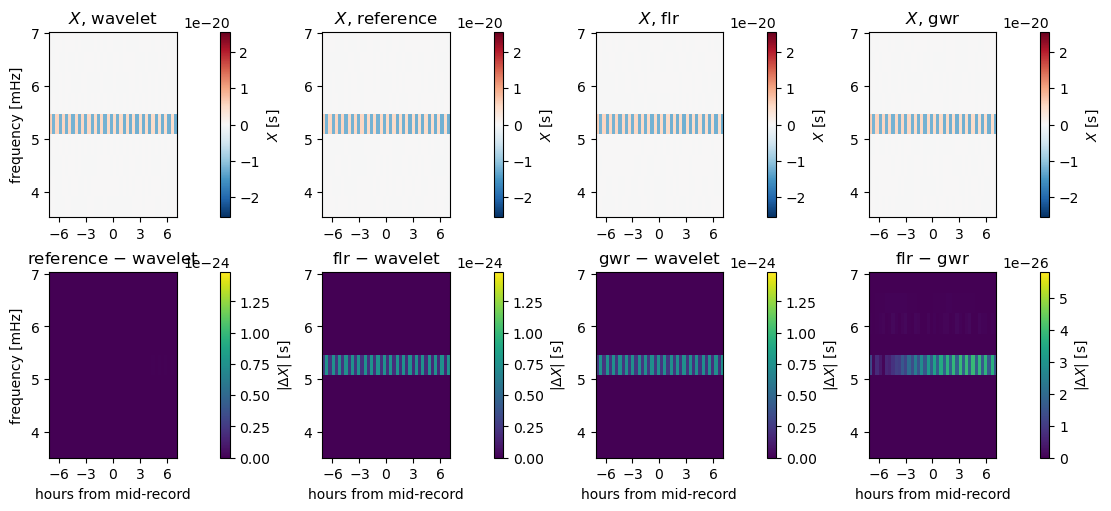

In [16]:
t_mid = cfg.Nt // 2 * cfg.dT
window = dict(xlim=(t_mid - 20 * cfg.dT, t_mid + 20 * cfg.dT),
              ylim=((cfg.m_bin - 4) * cfg.dF, (cfg.m_bin + 5) * cfg.dF))

methods = ["wavelet", "reference", "flr", "gwr"]
pairs = [("reference", "wavelet"), ("flr", "wavelet"), ("gwr", "wavelet"), ("flr", "gwr")]
diffs = {pair: grids[pair[0]][0] - grids[pair[1]][0] for pair in pairs}

# One colour scale per row, so equal colours mean equal values. flr - gwr
# is far smaller than the rest and keeps its own.
signal = np.abs(apply_wdm_cut(grids["wavelet"][0], cut)).max()
residual = max(np.abs(apply_wdm_cut(diffs[pair], cut)).max() for pair in pairs[:3])

fig, axes = plt.subplots(2, 4, figsize=(11, 5), layout="constrained")
for ax, name in zip(axes[0], methods):
    time_frequency_plot(wdm, grids[name][0], figax=(fig, ax), part="real",
                        cmap="RdBu_r", vmin=-signal, vmax=signal, label="$X$ [s]")
    ax.set(title=f"$X$, {name}", **window)
for k, (ax, pair) in enumerate(zip(axes[1], pairs)):
    time_frequency_plot(wdm, diffs[pair], figax=(fig, ax), part="abs", cmap="viridis",
                        vmin=0, vmax=residual if k < 3 else None, label=r"$|\Delta X|$ [s]")
    ax.set(title=f"{pair[0]} $-$ {pair[1]}", **window)
hours, mhz = [-6, -3, 0, 3, 6], [4, 5, 6, 7]
for ax in axes.flat:
    ax.set_xticks([t_mid + 3600 * h for h in hours], labels=[f"${h}$" for h in hours])
    ax.set_yticks([m * 1e-3 for m in mhz], labels=[f"${m}$" for m in mhz])
    ax.set(xlabel="", ylabel="")
for ax in axes[1]:
    ax.set_xlabel("hours from mid-record")
for ax in axes[:, 0]:
    ax.set_ylabel("frequency [mHz]")
plt.show()

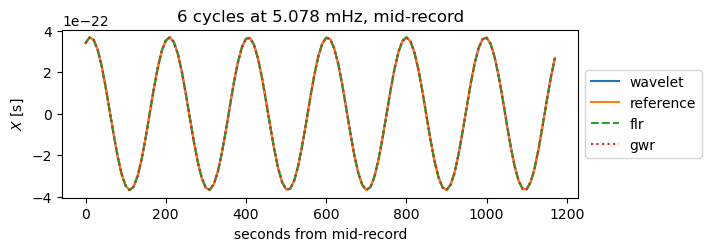

: 

In [ ]:
n_cycles = 6
span = int(n_cycles / cfg.f_gb / cfg.dt)
mid = cfg.N // 2
sl = slice(mid, mid + span)
seconds = cfg.padded_times[sl] - cfg.padded_times[mid]

fig, ax = plt.subplots(figsize=(7, 2.4), layout="constrained")
for name, style in (("wavelet", "-"), ("reference", "-"), ("flr", "--"), ("gwr", ":")):
    ax.plot(seconds, np.asarray(wdm.idwt(grids[name][0]))[sl], ls=style, label=name)
ax.set(xlabel="seconds from mid-record", ylabel="$X$ [s]",
       title=f"{n_cycles} cycles at {cfg.f_gb * 1e3:.3f} mHz, mid-record")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

**Beyond this comparison.** Eq. 12 is itself an approximation: Cornish & Rubbo
drop the wave's effect on the spacecraft's own motion (their Eq. 9), terms of
the same order $h\,v/c$ as those above and in none of the codes. These are
differences between formulations; we make no claim about which is closer to
the ground truth.

Numerically the reference is exact to Eq. 12 up to its Gauss-Legendre rule,
which at $P = 12$ leaves $1.3\times10^{-10}$ on the worst link.